# Préparation de l'annotation

In [ ]:
import pandas as pd
import s3fs

fs = s3fs.S3FileSystem(
    endpoint_url="https://minio.lab.sspcloud.fr",
    client_kwargs={"region_name": "us-east-1"},
)

In [ ]:
all_samples = []

for year in range(2018, 2026):
    metadata_path = f"s3://mateomorin/legifrance/metadata/acco_metadata_{year}.parquet"
    metadata_year = pd.read_parquet(metadata_path, filesystem=fs)
    metadata_year = metadata_year[pd.col("Heures supplémentaires (contingent, majoration)")]
    metadata_year["year"] = year

    # Docx path
    DOC_PATH = "s3://mateomorin/legifrance/documents"
    metadata_year["dateSignature"] = pd.to_datetime(metadata_year["dateSignature"])
    metadata_year["moisSignature"] = metadata_year["dateSignature"].dt.month.astype(str).str.zfill(2)
    metadata_year["docx_path"] = DOC_PATH + f"/{year}/" + metadata_year['moisSignature'] + "/" + metadata_year['cid'] + ".docx"
    
    all_samples.append(metadata_year[["reference", "year", "docx_path"]].sample(50, random_state=42))

all_samples = pd.concat(all_samples)
all_samples.to_csv("all_samples.csv", index=False)

In [ ]:
for file_s3, reference in zip(all_samples["docx_path"].values, all_samples["reference"].values):
    file_local = f"doc_samples/{reference}.docx"
    fs.download(file_s3, file_local)

In [ ]:
all_samples.reset_index(drop=True, inplace=True)

# Analyse des annotations

### Présentation générale

In [ ]:
import pandas as pd

annotations = pd.read_excel(
    "sources/annotations/Annotations_heures_supp.xlsx",
    sheet_name="Contingent",
)

In [ ]:
annotations.rename(columns={"presence_contingent_conventionnel ": "presence_contingent_conventionnel"}, inplace=True)
annotations = annotations[~annotations["presence_contingent_conventionnel"].isna()]
annotations.drop(columns=["Unnamed: 6"], inplace=True)

In [36]:
annotations["reference"].nunique()

200

In [37]:
annotations

,reference,presence_contingent_conventionnel,categorie_ou_population,nombre_heures,periode,remarque
0,A03118007022,False,NaN,NaN,NaN,Hors thème
1,A04418009590,False,NaN,NaN,NaN,Avenant avec information manquante
2,A04518003775,False,NaN,NaN,NaN,Pas heures supplémentaires au sens contingent ...
3,A07118002627,False,NaN,NaN,NaN,Avenant avec information manquante
4,A07518031240,True,Ensemble du personnel,330.0,annuel,NaN
...,...,...,...,...,...,...
395,T59L18000270,True,Tous les collaborateurs,220.0,annuelle,NaN
396,T59L21012704,True,Tous les salariés,350.0,annuelle,NaN
397,T59L25068200,False,NaN,NaN,NaN,Majoration
398,T59L25068789,True,Tous les salariés,130.0,annuelle,NaN


In [ ]:
all_samples = pd.read_csv("sources/annotations/all_samples.csv")
annotations = annotations.merge(all_samples, on="reference", how="left")

In [40]:
annotations["year"].value_counts()

year
2018    29
2021    28
2019    27
2024    26
2022    25
2023    23
2025    23
2020    21
Name: count, dtype: int64

In [57]:
import matplotlib.pyplot as plt

def present_annotations(extraction):
    n_accords = extraction["reference"].nunique()

    presence_totale = extraction["presence_contingent_conventionnel"].sum()
    presence_moyenne = round(extraction["presence_contingent_conventionnel"].mean() * 100, 2)

    print(f"Sur {n_accords} accords dans le thème des heures supplémentaires, {presence_totale} recensent un contingent conventionnel, soit {presence_moyenne}%.")

    # Définition des bornes de 50 à 600 avec un pas de 25
    bins = range(50, 625, 25)

    plt.figure(figsize=(10, 5))

    # Filtrage entre 50 et 600 h et tracé de l'histogramme
    data = extraction.query("50 <= nombre_heures <= 600")["nombre_heures"]

    data.hist(
        bins=bins,
        color="#2b5c8f",
        edgecolor="white",
        grid=True,
    )

    plt.title("Répartition des contingents annuels d'heures supplémentaires", fontsize=13, fontweight="bold", pad=12)
    plt.xlabel("Nombre d'heures", labelpad=8)
    plt.ylabel("Nombre de contingents mentionnés", labelpad=8)
    plt.xticks(range(50, 625, 50))
    plt.grid(alpha=0.5, linestyle="--")
    plt.tight_layout()
    plt.show()

Sur 200 accords dans le thème des heures supplémentaires, 127 recensent un contingent conventionnel, soit 62.87%.


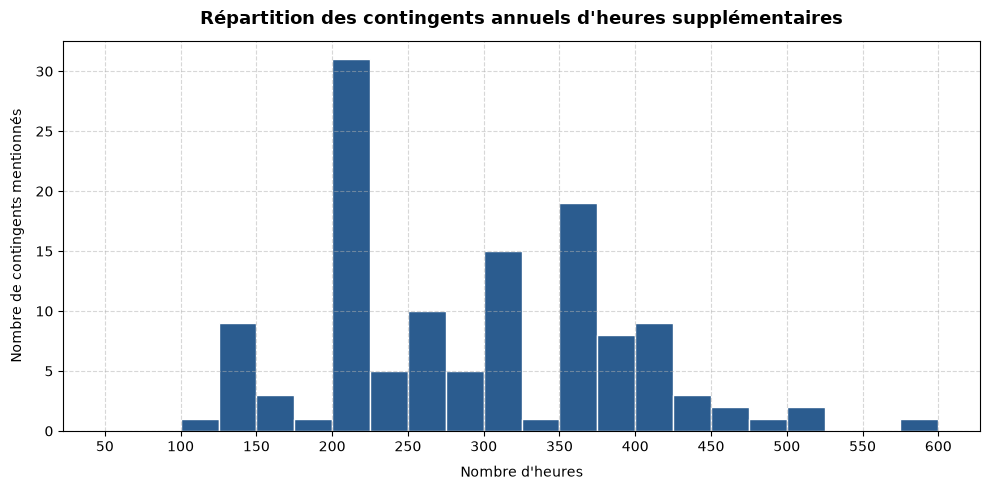

In [58]:
present_annotations(annotations)

## Contrôle des outputs IA

In [ ]:
import pandas as pd

annotations = pd.read_excel(
    "sources/annotations/Annotations_heures_supp.xlsx",
    sheet_name="Contingent",
)

annotations.rename(columns={"presence_contingent_conventionnel ": "presence_contingent_conventionnel"}, inplace=True)
annotations = annotations[~annotations["presence_contingent_conventionnel"].isna()]
annotations.drop(columns=["Unnamed: 6"], inplace=True)

In [2]:
import s3fs

fs = s3fs.S3FileSystem(
    endpoint_url="https://minio.lab.sspcloud.fr",
    client_kwargs={"region_name": "us-east-1"},
)

In [3]:
all_extractions = []

for year in range(2018, 2026):
    extraction_path = f"s3://mateomorin/legifrance/extraction_contingent/year={year}/extraction_{year}.parquet"
    extraction_year = pd.read_parquet(extraction_path, filesystem=fs)
    all_extractions.append(extraction_year)

all_extractions = pd.concat(all_extractions)

In [4]:
comparaison = annotations.merge(all_extractions, how="left", on="reference")
comparaison.info()

<class 'pandas.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 13 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   reference                            202 non-null    str    
 1   presence_contingent_conventionnel_x  202 non-null    object 
 2   categorie_ou_population              123 non-null    str    
 3   nombre_heures                        126 non-null    float64
 4   periode                              126 non-null    str    
 5   remarque                             79 non-null     str    
 6   anneeSignature                       202 non-null    int64  
 7   presence_contingent_conventionnel_y  202 non-null    bool   
 8   contingents                          202 non-null    str    
 9   citation_exacte                      198 non-null    str    
 10  justification_ou_reserve             195 non-null    str    
 11  n_chunks                             202 no

In [5]:
comparaison.rename(
    columns={
        "nombre_heures": "nombre_heures_annot",
        "presence_contingent_conventionnel_x": "presence_contingent_conventionnel_annot",
        "presence_contingent_conventionnel_y":  "presence_contingent_conventionnel_llm",
    },
    inplace=True
)

In [6]:
import json

contingents = comparaison["contingents"].to_list()
contingents = [json.loads(chaine) for chaine in contingents]
comparaison["contingents"] = contingents
comparaison = comparaison.explode("contingents")

df_dict = comparaison["contingents"].apply(
    lambda x: x if isinstance(x, dict) else {}
).apply(pd.Series)

comparaison = pd.concat([comparaison.drop(columns=["contingents"]), df_dict], axis=1)
comparaison.rename(
    columns={
        "nombre_heures": "nombre_heures_llm"
    },
    inplace=True
)

del df_dict

In [9]:
comparaison.drop_duplicates("reference", keep=False, inplace=True)

In [10]:
comparaison.columns

Index(['reference', 'presence_contingent_conventionnel_annot',
       'categorie_ou_population', 'nombre_heures_annot', 'periode', 'remarque',
       'anneeSignature', 'presence_contingent_conventionnel_llm',
       'citation_exacte', 'justification_ou_reserve', 'n_chunks', 'erreur',
       'categorie_ou_population', 'nombre_heures_llm', 'periode'],
      dtype='str')

In [15]:
(comparaison["presence_contingent_conventionnel_annot"] != comparaison["presence_contingent_conventionnel_llm"]).mean()*100

np.float64(4.2105263157894735)

In [14]:
comparaison[comparaison["presence_contingent_conventionnel_annot"] != comparaison["presence_contingent_conventionnel_llm"]].to_dict(orient="index")

/tmp/ipykernel_128669/1582650761.py:1: UserWarning: DataFrame columns are not unique, some columns will be omitted.
  comparaison[comparaison["presence_contingent_conventionnel_annot"] != comparaison["presence_contingent_conventionnel_llm"]].to_dict(orient="index")


{24: {'reference': 'T00422000937',
  'presence_contingent_conventionnel_annot': True,
  'categorie_ou_population': nan,
  'nombre_heures_annot': 220.0,
  'periode': nan,
  'remarque': nan,
  'anneeSignature': 2021,
  'presence_contingent_conventionnel_llm': False,
  'citation_exacte': nan,
  'justification_ou_reserve': "Le texte mentionne explicitement que le contingent applicable est le 'contingent légal de 220 heures par an'. Conformément aux règles d'extraction, l'accord ne crée pas de règle propre à l'entreprise (contingent conventionnel) mais se contente de rappeler la limite fixée par la loi.",
  'n_chunks': 5,
  'erreur': None,
  'nombre_heures_llm': nan},
 36: {'reference': 'T00824060231',
  'presence_contingent_conventionnel_annot': True,
  'categorie_ou_population': nan,
  'nombre_heures_annot': 423.0,
  'periode': nan,
  'remarque': nan,
  'anneeSignature': 2024,
  'presence_contingent_conventionnel_llm': False,
  'citation_exacte': '',
  'justification_ou_reserve': "Le text

Les erreurs proviennent de l'extraction RAG.

In [18]:
comparaison[pd.col("presence_contingent_conventionnel_llm") & (pd.col("nombre_heures_annot") != pd.col("nombre_heures_llm"))]

,reference,presence_contingent_conventionnel_annot,categorie_ou_population,nombre_heures_annot,periode,remarque,anneeSignature,presence_contingent_conventionnel_llm,citation_exacte,justification_ou_reserve,n_chunks,erreur,categorie_ou_population,nombre_heures_llm,periode
127,T03322010177,True,Tous les salariés,220.0,annuel,Contingent indiqué comme non fixé pour appliqu...,2022,True,"Ainsi, le présent accord a pour objet d’augmen...",L'accord prévoit explicitement de déroger au c...,5,None,Salarié,400.0,Année civile
141,T03620000541,True,Tous les salariés,220.0,annuel,NaN,2020,True,Le présent accord a pour objet d’augmenter le ...,L'accord mentionne le contingent de la convent...,5,None,salarié,350.0,annuelle
201,T59V23060168,True,Tous les salariés,NaN,NaN,NaN,2023,True,En application des dispositions de l’article L...,L'accord prévoit explicitement un rehaussement...,5,None,Salariés à temps complet,515.0,Annuelle


Le LLM a tout le temps bon, ce ne sont que des erreurs d'annotation.

**Conclusion : le LLM n'est pas la brique limitante, c'est plutôt un problème côté conversion et RAG** 